
# HR Analytics: Job Change Prediction Using Machine Learning

## 1. Project Overview

### Problem Statement

Organizations invest significant time and resources in recruiting, training, and developing employees. However, candidates may have different career aspirations and employment intentions.

Identifying candidates who are actively looking for a job change can help organizations understand workforce mobility and improve their recruitment and talent management strategies.

This project aims to develop a Machine Learning classification model that predicts whether a candidate is looking for a new job based on demographic information, educational background, professional experience, and other relevant attributes.

### Project Objectives

1. Perform Exploratory Data Analysis (EDA) to understand candidate characteristics.
2. Identify patterns associated with job-change intentions.
3. Handle missing values and preprocess categorical and numerical features.
4. Build and compare multiple Machine Learning classification algorithms.
5. Evaluate model performance using appropriate classification metrics.
6. Identify important features influencing model predictions.
7. Optimize and save the final trained model.

### Dataset Description

The dataset contains candidate information collected by a company that provides training programs in Big Data and Data Science.

The objective is to predict whether a candidate is looking for a new employment opportunity.

### Target Variable

- **0:** Candidate is not looking for a job change.
- **1:** Candidate is looking for a job change.

### Problem Type

Supervised Machine Learning – Binary Classification.


## 2. Data Collection

In this section, we will import the necessary Python libraries and load the HR Analytics dataset.

The dataset contains candidate information that will be used to understand and predict job-change intentions.

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

### 2.1 Loading the Dataset

We will load the HR Analytics dataset using Pandas and inspect the first five records to understand its structure.

In [4]:
# Load the dataset

df = pd.read_csv('/content/drive/MyDrive/AI_ML/Employee Attrition Prediction/dataset/aug_train.csv')

# Display first five records
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


### 2.2 Dataset Overview

We will examine the number of records, features, data types, and memory usage of the dataset.

This will help us understand the overall structure of the data before performing Exploratory Data Analysis.

In [5]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

Dataset Shape: (19158, 14)

Column Names:
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   comp

### 2.3 Checking Missing Values

Before performing EDA, we need to identify missing values in the dataset.

Missing values can affect model performance, so we will analyse their distribution and handle them during data preprocessing.

In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
company_type,6140,32.049274
company_size,5938,30.994885
gender,4508,23.530640
major_discipline,2813,14.683161
education_level,460,2.401086
last_new_job,423,2.207955
enrolled_university,386,2.014824
experience,65,0.339284
enrollee_id,0,0.000000
city,0,0.000000


### 2.4 Checking Duplicate Records

Duplicate records can introduce bias into our analysis and model training.

We will check whether the dataset contains duplicate rows and duplicate candidate IDs.


In [7]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate candidate IDs
print("Duplicate Enrollee IDs:", df['enrollee_id'].duplicated().sum())

Duplicate Rows: 0
Duplicate Enrollee IDs: 0


### 2.5 Statistical Summary

We will use descriptive statistics to understand the distribution of numerical variables, including their mean, standard deviation, minimum, maximum, and quartiles.

In [8]:
# Statistical summary of numerical columns

df.describe()

,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


### 2.6 Categorical Feature Summary

We will examine the categorical variables using descriptive statistics.

This will help us understand the number of unique categories, most frequently occurring values, and their frequencies.

In [9]:
# Statistical summary of categorical columns

df.describe(include='object')

,city,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job
count,19158,14650,19158,18772,18698,16345,19093,13220,13018,18735
unique,123,3,2,3,5,6,22,8,6,6
top,city_103,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1
freq,4355,13221,13792,13817,11598,14492,3286,3083,9817,8040


### 2.7 Data Collection Summary

The HR Analytics dataset has been successfully loaded and inspected.

Key findings:

1. The dataset contains 19,158 records and 14 columns.
2. It consists of numerical and categorical features.
3. Several features contain missing values.
4. No duplicate rows or duplicate enrollee IDs were found.
5. The target variable is imbalanced, with approximately 24.93% positive cases.
6. The dataset contains candidate demographic, educational, and professional information.

The dataset is now ready for Exploratory Data Analysis (EDA).

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns, distributions, relationships, and potential insights within the dataset.

### 3.1 Target Variable Distribution

Our target variable is `target`.

- 0: Candidate is not looking for a job change.
- 1: Candidate is looking for a job change.

We will analyse the distribution of both classes to understand whether the dataset is balanced or imbalanced.

target
0.0    14381
1.0     4777
Name: count, dtype: int64

Target Percentage:
target
0.0    75.065247
1.0    24.934753
Name: proportion, dtype: float64


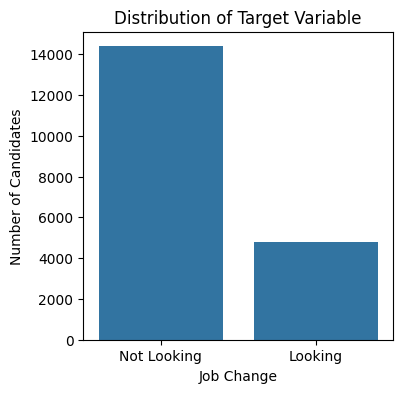

In [11]:
# Count the target classes

print(df['target'].value_counts())

# Calculate percentage distribution
print("\nTarget Percentage:")
print(df['target'].value_counts(normalize=True) * 100)

# Visualize target distribution
plt.figure(figsize=(4, 4))

sns.countplot(data=df, x='target')

plt.title('Distribution of Target Variable')
plt.xlabel('Job Change')
plt.ylabel('Number of Candidates')
plt.xticks([0, 1], ['Not Looking', 'Looking'])

plt.show()

### 3.2 Numerical Feature Distribution

We will analyse the distribution of numerical features using histograms.

This will help us understand the spread, concentration, and potential skewness of numerical variables.

To avoid repetitive code, we will create a reusable function that accepts a list of numerical columns and generates their distribution plots.

In [15]:
def plot_histogram(data, feature):
    plt.figure(figsize=(4, 3))
    sns.histplot(data=data, x=feature, bins=30, kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

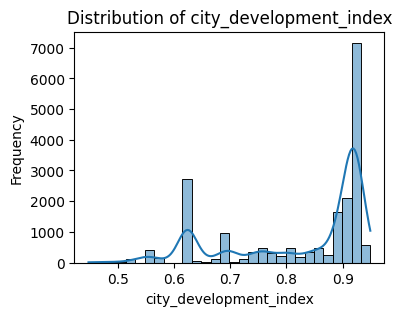

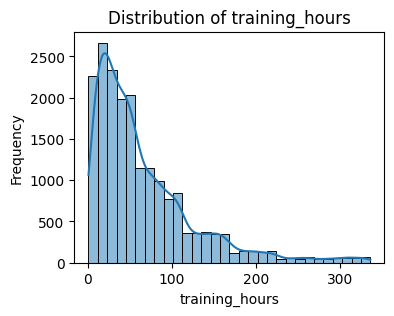

In [16]:
plot_histogram(df, 'city_development_index')
plot_histogram(df, 'training_hours')

### 3.3 Outlier Detection Using Boxplots

Boxplots help identify potential outliers in numerical features.

We will create a reusable function to visualize the distribution and potential outliers of individual numerical features.

In [19]:
def plot_boxplot(data, feature):

    plt.figure(figsize=(4, 2))

    sns.boxplot(data=data, x=feature)

    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)

    plt.show()

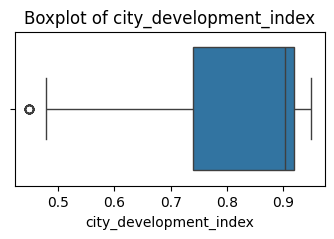

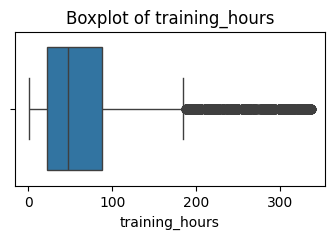

In [20]:
plot_boxplot(df, 'city_development_index')
plot_boxplot(df, 'training_hours')

### 3.4 Categorical Feature Analysis

Categorical feature analysis helps us understand the distribution of different categories within the dataset.

In this section, we will analyse categorical variables such as gender, education level, relevant experience, and university enrollment.

We will use countplots to visualize the frequency of each category.

A reusable plotting function will be created to generate countplots for individual categorical features.

**Objectives:**
1. Understand the distribution of categorical variables.
2. Identify the most frequently occurring categories.
3. Observe any imbalance among different categories.
4. Identify patterns that may be useful for predicting job-change intentions.

In [23]:
def plot_countplot(data, feature):

    plt.figure(figsize=(5, 2))

    sns.countplot(
        data=data,
        x=feature,
        order=data[feature].value_counts().index
    )

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

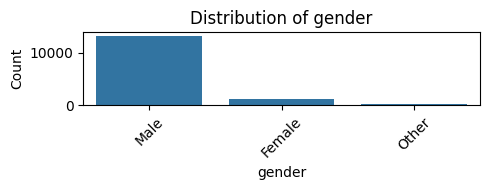

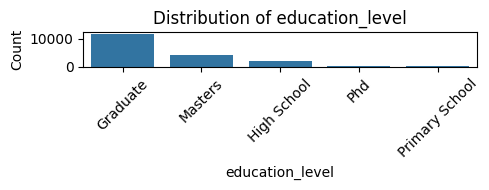

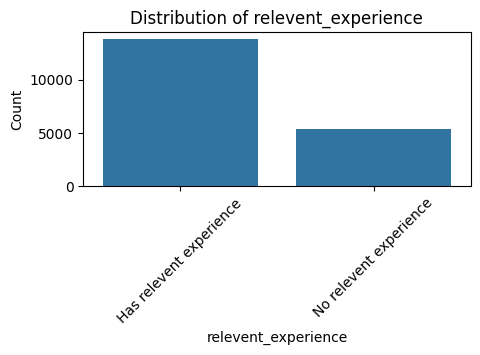

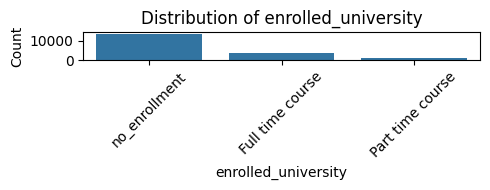

In [24]:
plot_countplot(df, 'gender')
plot_countplot(df, 'education_level')
plot_countplot(df, 'relevent_experience')
plot_countplot(df, 'enrolled_university')

### 3.5 Analysis of Professional Background

In this section, we will analyse additional categorical features related to the candidate's professional background.

The features include:

1. Major Discipline
2. Experience
3. Company Size
4. Company Type
5. Last New Job

These visualizations will help us understand the professional profiles of candidates in the dataset.

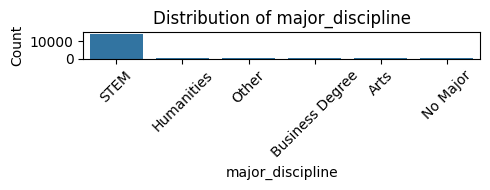

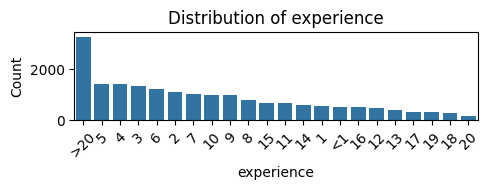

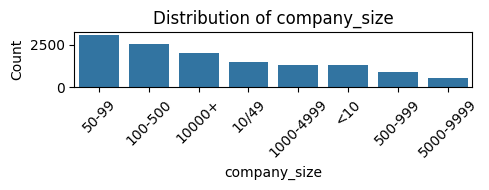

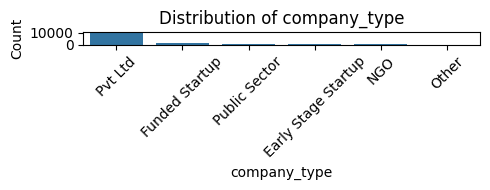

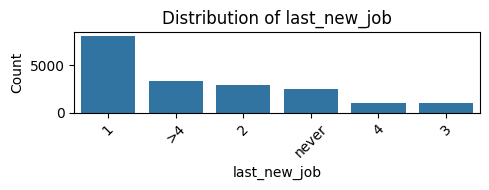

In [25]:
plot_countplot(df, 'major_discipline')
plot_countplot(df, 'experience')
plot_countplot(df, 'company_size')
plot_countplot(df, 'company_type')
plot_countplot(df, 'last_new_job')

EDA observations – Professional Background
1. Major Discipline: STEM candidates dominate the dataset.
2. Experience: Candidates with more than 20 years of experience form the largest group.
3. Company Size: The 50–99 employee category is the most frequent, followed by 100–500.
4. Company Type: Pvt Ltd companies dominate the dataset.
5. Last New Job: Candidates whose previous job change was one year ago form the largest group.

### 3.6 Bivariate Analysis – Categorical Features vs Target

In this section, we will analyse the relationship between categorical features and the target variable.

We will use countplots with the target variable as the hue.

This will help us compare candidates who are looking for a job change (1) with those who are not (0) across different categories.

In [28]:
def plot_categorical_vs_target(data, feature):

    plt.figure(figsize=(5, 2))

    sns.countplot(
        data=data,
        x=feature,
        hue='target'
    )

    plt.title(f'{feature} vs Job Change')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.legend(title='Job Change', labels=['No', 'Yes'])

    plt.tight_layout()
    plt.show()

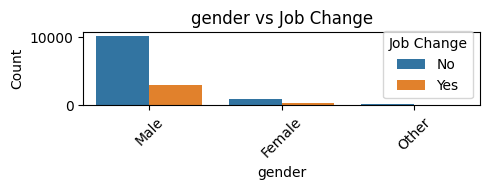

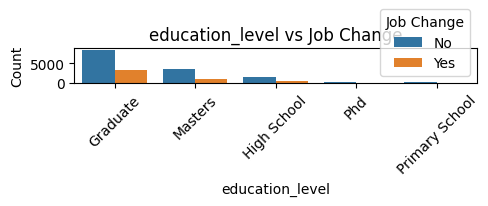

In [29]:
plot_categorical_vs_target(df, 'gender')
plot_categorical_vs_target(df, 'education_level')

1. Gender vs Job Change
- Male candidates contribute the largest number of job-change cases.
- Female candidates have fewer job-change cases in absolute numbers.
- The number of candidates in the Other category is very small.
2. Education Level vs Job Change
- Graduates account for the largest number of candidates looking for a job change.
- Masters candidates form the second-largest group.
- Other education categories have comparatively fewer observations.
Important analytical point: These are absolute counts, not percentages. We cannot conclude that one gender or education group is more likely to change jobs just from these plots. We will examine category-wise percentages later.

#### Analysis of Professional Experience vs Job Change

We will investigate how professional experience, university enrollment, and previous employment history relate to candidates' job-change intentions.

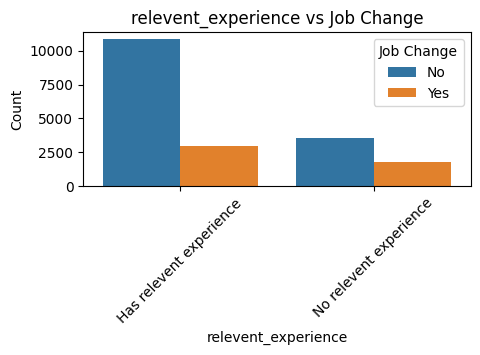

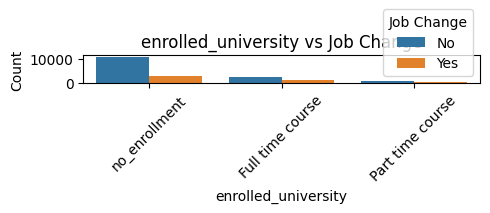

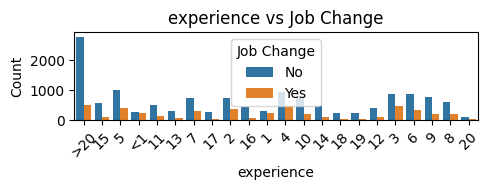

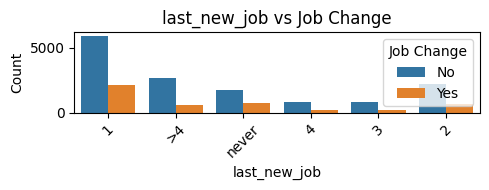

In [31]:
plot_categorical_vs_target(df, 'relevent_experience')
plot_categorical_vs_target(df, 'enrolled_university')
plot_categorical_vs_target(df, 'experience')
plot_categorical_vs_target(df, 'last_new_job')

EDA observations
1. Relevant Experience
- Candidates with relevant experience form the larger group.
- Candidates without relevant experience also show a considerable number of job-change intentions.
- We should compare percentages to understand the difference more accurately.
2. University Enrollment
- Candidates not enrolled in university form the largest group.
- Full-time and part-time students represent smaller groups.
3. Experience
- Candidates with less than one year of experience form a large group.
- Job-change cases are visible across multiple experience levels.
- Experience alone may not explain job-change intentions.
4. Last New Job
- Candidates whose last job change was one year ago form the largest group.
- Candidates with more than four years since their last job change also represent a substantial group.

#### Company Characteristics and Major Discipline vs Job Change

In this section, we will analyse the relationship between company-related attributes, major discipline, and job-change intentions.

The features considered are:

1. Major Discipline
2. Company Size
3. Company Type

This analysis will help us understand how candidates' educational backgrounds and organizational environments relate to their job-change intentions.

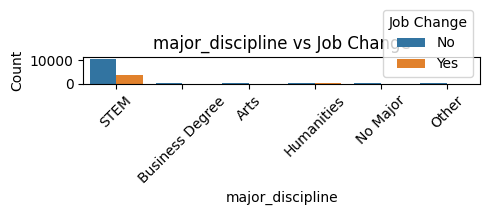

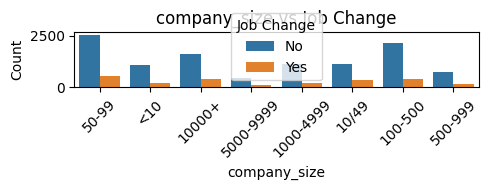

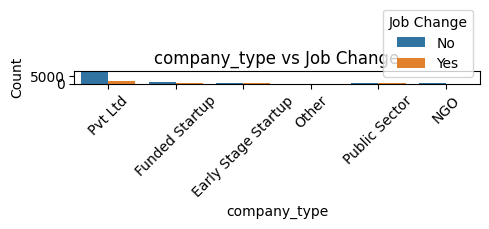

In [32]:
plot_categorical_vs_target(df, 'major_discipline')
plot_categorical_vs_target(df, 'company_size')
plot_categorical_vs_target(df, 'company_type')

EDA observations
1. Major Discipline vs Job Change
- STEM candidates account for the majority of job-change cases.
- Other disciplines have significantly fewer observations.
- STEM dominates the dataset, so absolute counts should be interpreted carefully.
2. Company Size vs Job Change
- Candidates working in companies with 50–99 employees form the largest group.
- Job-change cases are present across all company-size categories.
- Smaller and larger organizations both have candidates interested in changing jobs.
3. Company Type vs Job Change
- Pvt Ltd companies dominate the dataset.
- Funded startups and public-sector organizations have fewer observations.
- Job-change intentions occur across different company types.

### 3.7 Numerical Features vs Target

In this section, we will analyse the relationship between numerical features and the target variable.

We will use boxplots to compare the distributions of numerical features across the two target classes.

The features considered are:

1. City Development Index
2. Training Hours

This analysis will help us identify differences in the distributions of these features between candidates looking for a job change and those who are not.

In [36]:
def plot_numerical_vs_target(data, feature):

    plt.figure(figsize=(4, 2))

    sns.boxplot(data=data, x='target', y=feature)

    plt.title(f'{feature} vs Job Change')
    plt.xlabel('Job Change (0 = No, 1 = Yes)')
    plt.ylabel(feature)

    plt.show()

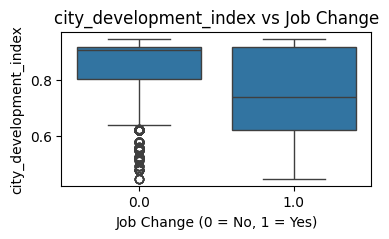

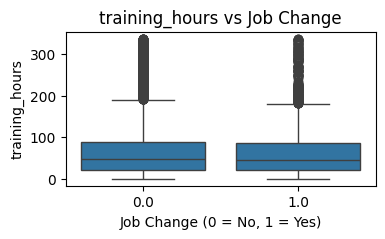

In [37]:
plot_numerical_vs_target(df, 'city_development_index')
plot_numerical_vs_target(df, 'training_hours')

EDA Observations
1. City Development Index vs Job Change
- Candidates not looking for a job change (0) generally belong to cities with a higher development index.
- Candidates looking for a job change (1) show a lower median city development index.
- This suggests that candidates from less-developed cities may have a greater tendency to seek new employment opportunities.
2. Training Hours vs Job Change
- Both groups have relatively similar median training hours.
- Their distributions overlap considerably.
- Both groups contain several high-value outliers.
- Training hours alone may not strongly distinguish candidates looking for a job change.
Key finding: city_development_index appears to show a more noticeable difference between the two target groups than training_hours.

### 3.8 Correlation Analysis

Correlation analysis helps us understand the strength and direction of relationships between numerical variables.

We will use a correlation matrix and heatmap to visualize these relationships.

This analysis will help identify highly correlated numerical features and understand their relationship with the target variable.

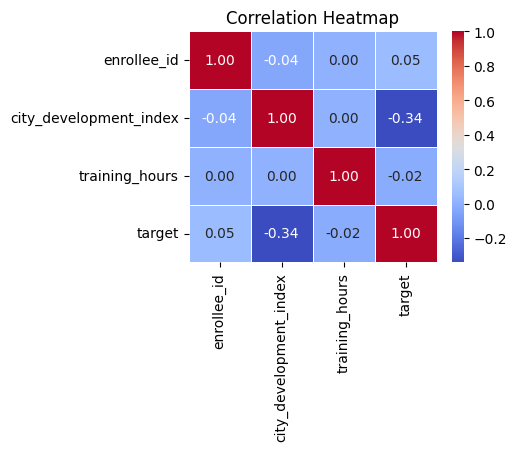

In [41]:
# Calculate correlation matrix
correlation = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(4, 3))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

Key findings:
1. city_development_index has a negative correlation (-0.34) with job-change intention. Candidates from cities with lower development indices tend to show greater job-change intention.
2. training_hours has almost zero linear correlation with the target.
3. enrollee_id is an identifier and should not be used as a predictive feature.

### 3.9 Exploratory Data Analysis – Summary

The following insights were obtained from the Exploratory Data Analysis:

1. The target variable is imbalanced, with approximately 75% candidates not looking for a job change and 25% looking for a job change.
2. Male candidates and STEM graduates dominate the dataset.
3. Most candidates have relevant professional experience.
4. Most candidates are not enrolled in university courses.
5. Pvt Ltd companies represent the largest company category.
6. Training hours are positively skewed and contain several potential outliers.
7. City Development Index shows a moderate negative correlation (-0.34) with the target variable.
8. Training hours show almost no linear correlation (-0.02) with the target.
9. Several categorical features contain missing values that require appropriate treatment.

### Conclusion

EDA helped us understand the dataset, identify class imbalance, examine feature distributions, and discover potential relationships between candidate characteristics and job-change intentions.

The next phase will focus on preparing the dataset for Machine Learning.

## 4. Data Preprocessing

Data preprocessing involves preparing the dataset for Machine Learning algorithms.

In this phase, we will:
1. Remove irrelevant features.
2. Separate independent and dependent variables.
3. Split the dataset into training and testing sets.
4. Handle missing values.
5. Encode categorical variables.
6. Prepare numerical features for model training.

### 4.1 Feature Selection and Target Separation

The column `enrollee_id` is a unique identifier and does not contribute meaningful predictive information.

We will remove this column and separate the remaining independent features (X) from the target variable (y).

In [42]:
# Remove irrelevant column
df = df.drop(columns=['enrollee_id'])

# Separate independent and dependent variables
X = df.drop(columns=['target'])
y = df['target']

# Check shapes
print("Independent Features:", X.shape)
print("Target Variable:", y.shape)

Independent Features: (19158, 12)
Target Variable: (19158,)


### 4.2 Train-Test Split

We will split the dataset into training and testing sets.

- 80% of the data will be used for model training.
- 20% will be reserved for model testing.

Stratified sampling will be used to maintain the original target-class distribution in both sets.

A random state will ensure reproducibility.

In [43]:
from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset dimensions

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (15326, 12)
X_test: (3832, 12)
y_train: (15326,)
y_test: (3832,)


### 4.3 Checking Target Distribution After Splitting

We will compare the target-class distribution in the original, training, and testing datasets.

This ensures that stratified sampling has maintained a similar proportion of both classes across all datasets.

In [44]:
# Compare target distribution

print("Original Dataset:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining Dataset:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Dataset:")
print(y_test.value_counts(normalize=True) * 100)

Original Dataset:
target
0.0    75.065247
1.0    24.934753
Name: proportion, dtype: float64

Training Dataset:
target
0.0    75.061986
1.0    24.938014
Name: proportion, dtype: float64

Testing Dataset:
target
0.0    75.078288
1.0    24.921712
Name: proportion, dtype: float64


### 4.4 Identifying Numerical and Categorical Features

Machine Learning algorithms require appropriate preprocessing of numerical and categorical features.

We will identify these features separately so that different preprocessing techniques can be applied to each group.

- Numerical features: Median imputation.
- Categorical features: Most frequent value imputation and One-Hot Encoding.

In [45]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features: ['city_development_index', 'training_hours']

Categorical Features: ['city', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']

Number of Numerical Features: 2
Number of Categorical Features: 10


### 4.5 Building the Preprocessing Pipeline

Different preprocessing techniques are required for numerical and categorical features.

We will create two separate pipelines:

**1. Numerical Pipeline**
- Missing value imputation using Median.
- Feature scaling using StandardScaler.

**2. Categorical Pipeline**
- Missing value imputation using Most Frequent value.
- One-Hot Encoding to convert categorical variables into numerical representations.

Finally, ColumnTransformer will combine both pipelines into a single preprocessing object.

This approach ensures consistent preprocessing of training and testing data and helps prevent data leakage.

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing pipeline
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

### 4.6 Applying Preprocessing

We will now apply the preprocessing pipeline to our training and testing datasets.

- The pipeline will be fitted on the training data using `fit_transform()`.
- The testing data will be transformed using `transform()`.

This ensures that the imputation values, scaling parameters, and encoding categories are learned only from the training data, preventing data leakage.

In [47]:
# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

# Check transformed dimensions
print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (15326, 185)
Testing Data Shape: (3832, 185)


### 4.7 Inspecting Processed Features

After applying One-Hot Encoding, the number of features has increased.

We will extract the transformed feature names from the preprocessing pipeline and inspect them to understand the final feature representation.

In [48]:
# Extract feature names
feature_names = preprocessor.get_feature_names_out()

# Display first 20 features
print("First 20 Processed Features:\n")
print(feature_names[:20])

# Total number of features
print("\nTotal Processed Features:", len(feature_names))

First 20 Processed Features:

['numerical__city_development_index' 'numerical__training_hours'
 'categorical__city_city_1' 'categorical__city_city_10'
 'categorical__city_city_100' 'categorical__city_city_101'
 'categorical__city_city_102' 'categorical__city_city_103'
 'categorical__city_city_104' 'categorical__city_city_105'
 'categorical__city_city_106' 'categorical__city_city_107'
 'categorical__city_city_109' 'categorical__city_city_11'
 'categorical__city_city_111' 'categorical__city_city_114'
 'categorical__city_city_115' 'categorical__city_city_116'
 'categorical__city_city_117' 'categorical__city_city_118']

Total Processed Features: 185


### 4.8 Data Preprocessing – Summary

The data preprocessing phase has been successfully completed.

Key operations performed:

1. Removed the irrelevant `enrollee_id` column.
2. Separated independent features (X) and target variable (y).
3. Split the dataset into 80% training and 20% testing data.
4. Used stratified sampling to maintain class distribution.
5. Identified 2 numerical and 10 categorical features.
6. Handled missing numerical values using Median Imputation.
7. Handled missing categorical values using Most Frequent Imputation.
8. Applied Standard Scaling to numerical features.
9. Applied One-Hot Encoding to categorical features.
10. Combined all preprocessing operations using ColumnTransformer.

The original 12 input features were transformed into 185 processed features.

The dataset is now ready for Machine Learning model development.

## 5. Machine Learning Model Building

In this phase, we will build and evaluate multiple supervised Machine Learning classification algorithms.

The following algorithms will be implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. XGBoost Classifier

A reusable function will be developed to train and evaluate each model using a consistent set of evaluation metrics.

This approach will help us compare the performance of different algorithms systematically.

In [50]:
# Import Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [51]:
# Import Evaluation Metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

### 5.2 Reusable Model Training and Evaluation Function

We will create a single function to train and evaluate different Machine Learning algorithms.

The function will accept the model name along with training and testing datasets.

It will automatically train the selected model, generate predictions, calculate evaluation metrics, and display the confusion matrix.

This approach eliminates repetitive code and ensures consistent evaluation across all models.

In [52]:
# Create a dictionary of Machine Learning models

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

In [53]:
def train_evaluate_model(model_name, X_train, X_test, y_train, y_test):

    # Select model
    model = models[model_name]

    # Train model
    model.fit(X_train, y_train)

    # Generate predictions
    y_pred = model.predict(X_test)

    # Generate probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }

    # Display metrics
    print(f"\n{model_name} - Evaluation Metrics")
    print("-" * 40)

    for metric, value in metrics.items():
        if metric != 'Model':
            print(f"{metric}: {value:.4f}")

    # Actual vs Predicted comparison
    comparison = pd.DataFrame({
        'Actual': y_test.values,
        'Predicted': y_pred
    })

    print("\nActual vs Predicted:")
    display(comparison.head(10))

    # Classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Not Looking', 'Looking']
    ).plot(cmap='Blues')

    plt.title(f'{model_name} - Confusion Matrix')
    plt.show()

    return model, metrics, comparison

### 5.3 Logistic Regression

We will begin model development with Logistic Regression.

The reusable training and evaluation function will train the model and automatically generate predictions, evaluation metrics, classification report, and confusion matrix.


Logistic Regression - Evaluation Metrics
----------------------------------------
Accuracy: 0.7758
Precision: 0.5866
Recall: 0.3403
F1 Score: 0.4307
ROC-AUC: 0.7931

Actual vs Predicted:


,Actual,Predicted
0,0.0,0.0
1,1.0,0.0
2,0.0,0.0
3,1.0,0.0
4,1.0,1.0
5,0.0,1.0
6,0.0,0.0
7,0.0,0.0
8,1.0,0.0
9,0.0,0.0



Classification Report:
              precision    recall  f1-score   support

         0.0       0.81      0.92      0.86      2877
         1.0       0.59      0.34      0.43       955

    accuracy                           0.78      3832
   macro avg       0.70      0.63      0.65      3832
weighted avg       0.75      0.78      0.75      3832



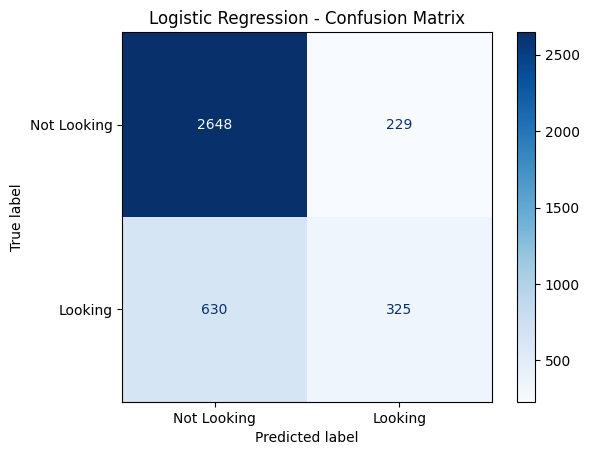

In [54]:
lr_model, lr_metrics, lr_comparison = train_evaluate_model(
    'Logistic Regression',
    X_train_processed,
    X_test_processed,
    y_train,
    y_test
)

### 5.4 Decision Tree Classifier

Decision Tree is a supervised Machine Learning algorithm that makes predictions using a tree-like structure.

It divides the dataset into smaller subsets based on feature conditions and uses decision rules to classify observations.

We will use Decision Tree Classifier to predict candidates' job-change intentions.


Decision Tree - Evaluation Metrics
----------------------------------------
Accuracy: 0.6960
Precision: 0.4389
Recall: 0.7895
F1 Score: 0.5642
ROC-AUC: 0.7820

Actual vs Predicted:


,Actual,Predicted
0,0.0,0.0
1,1.0,1.0
2,0.0,0.0
3,1.0,0.0
4,1.0,1.0
5,0.0,1.0
6,0.0,0.0
7,0.0,0.0
8,1.0,1.0
9,0.0,1.0



Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.66      0.77      2877
         1.0       0.44      0.79      0.56       955

    accuracy                           0.70      3832
   macro avg       0.67      0.73      0.67      3832
weighted avg       0.79      0.70      0.72      3832



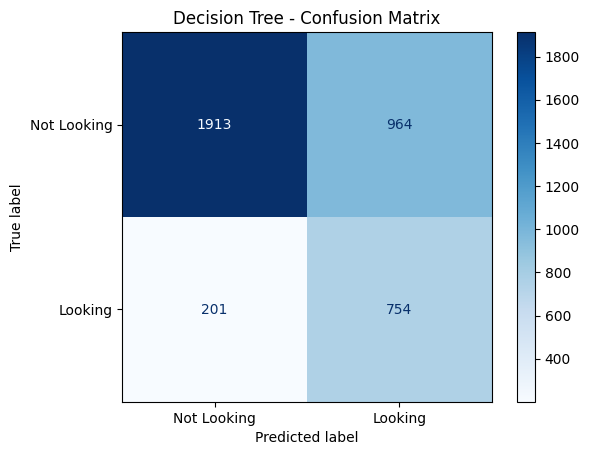

In [55]:
dt_model, dt_metrics, dt_comparison = train_evaluate_model(
    'Decision Tree',
    X_train_processed,
    X_test_processed,
    y_train,
    y_test
)

### 5.5 Random Forest Classifier

Random Forest is an ensemble Machine Learning algorithm that combines multiple Decision Trees to improve prediction performance.

Each tree is trained using different samples and feature subsets. The final prediction is obtained by combining the predictions of individual trees.

Random Forest generally provides better generalization and reduces overfitting compared to a single Decision Tree.

We will use Random Forest Classifier to predict candidates' job-change intentions.


Random Forest - Evaluation Metrics
----------------------------------------
Accuracy: 0.7657
Precision: 0.5225
Recall: 0.6942
F1 Score: 0.5962
ROC-AUC: 0.7990

Actual vs Predicted:


,Actual,Predicted
0,0.0,0.0
1,1.0,1.0
2,0.0,0.0
3,1.0,0.0
4,1.0,1.0
5,0.0,1.0
6,0.0,0.0
7,0.0,0.0
8,1.0,1.0
9,0.0,0.0



Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      0.79      0.83      2877
         1.0       0.52      0.69      0.60       955

    accuracy                           0.77      3832
   macro avg       0.70      0.74      0.72      3832
weighted avg       0.80      0.77      0.78      3832



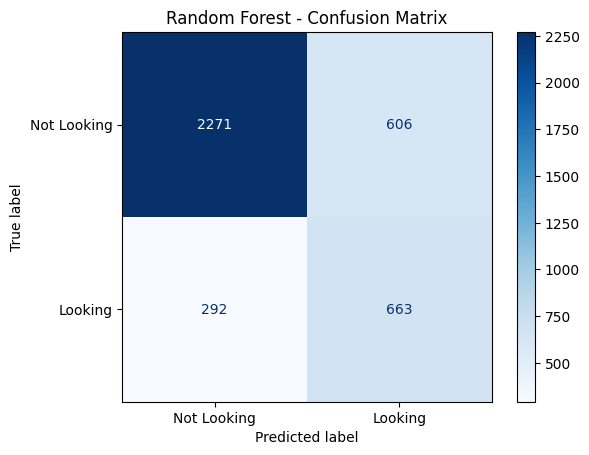

In [56]:
rf_model, rf_metrics, rf_comparison = train_evaluate_model(
    'Random Forest',
    X_train_processed,
    X_test_processed,
    y_train,
    y_test
)

### 5.6 XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an advanced ensemble Machine Learning algorithm based on gradient boosting.

It builds decision trees sequentially, where each new tree attempts to correct the errors made by previous trees.

XGBoost is widely used for structured and tabular datasets because of its predictive performance, regularization techniques, and computational efficiency.

We will use XGBoost Classifier to predict candidates' job-change intentions.


XGBoost - Evaluation Metrics
----------------------------------------
Accuracy: 0.7842
Precision: 0.5882
Recall: 0.4471
F1 Score: 0.5080
ROC-AUC: 0.8054

Actual vs Predicted:


,Actual,Predicted
0,0.0,0
1,1.0,1
2,0.0,0
3,1.0,0
4,1.0,1
5,0.0,1
6,0.0,0
7,0.0,0
8,1.0,0
9,0.0,0



Classification Report:
              precision    recall  f1-score   support

         0.0       0.83      0.90      0.86      2877
         1.0       0.59      0.45      0.51       955

    accuracy                           0.78      3832
   macro avg       0.71      0.67      0.68      3832
weighted avg       0.77      0.78      0.77      3832



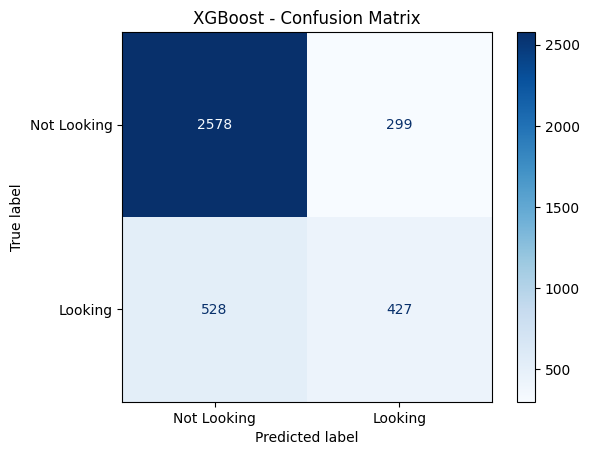

In [57]:
xgb_model, xgb_metrics, xgb_comparison = train_evaluate_model(
    'XGBoost',
    X_train_processed,
    X_test_processed,
    y_train,
    y_test
)

### 5.7 Model Performance Comparison

After training and evaluating all four classification algorithms, we will compare their performance using a consolidated results table.

The evaluation metrics include:

1. Accuracy
2. Precision
3. Recall
4. F1 Score
5. ROC-AUC Score

This comparison will help us identify the most suitable model for predicting job-change intentions.

In [58]:
# Combine evaluation results

results = pd.DataFrame([
    lr_metrics,
    dt_metrics,
    rf_metrics,
    xgb_metrics
])

# Sort models by F1 Score
results = results.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.765658,0.522459,0.694241,0.596223,0.799000
1,Decision Tree,0.695981,0.438882,0.789529,0.564160,0.781995
2,XGBoost,0.784186,0.588154,0.447120,0.508031,0.805401
3,Logistic Regression,0.775835,0.586643,0.340314,0.430749,0.793133


### 5.8 Model Performance Visualization

We will visualize the evaluation metrics of all four models using a bar chart.

This will make it easier to compare their predictive performance and identify the strongest candidate for further optimization.

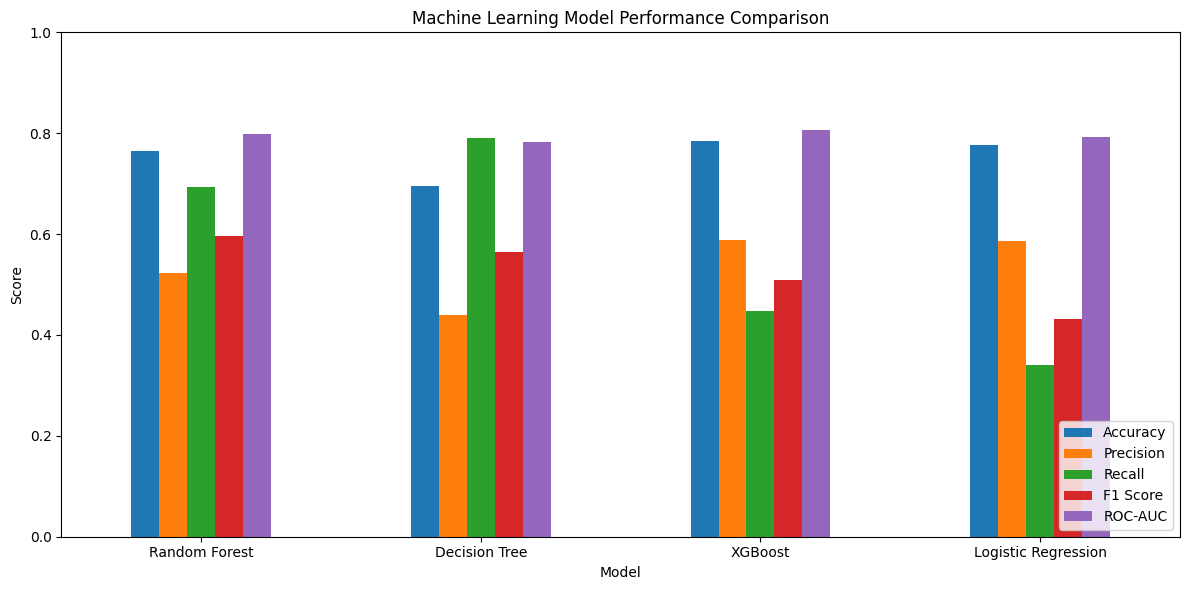

In [59]:
# Plot model performance

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Key findings
1. Random Forest: Best F1-score and a good balance between precision and recall.
2. Decision Tree: Highest recall, meaning it identifies more candidates looking for a job change.
3. XGBoost: Highest ROC-AUC and precision.
4. Logistic Regression: Good accuracy but relatively poor recall.

### 5.10 Feature Importance Analysis

Feature importance helps us identify which input variables contribute most to the predictions made by a Machine Learning model.

We will use the feature importance values provided by the Random Forest classifier.

The importance scores will be visualized to identify the top 20 influential features.

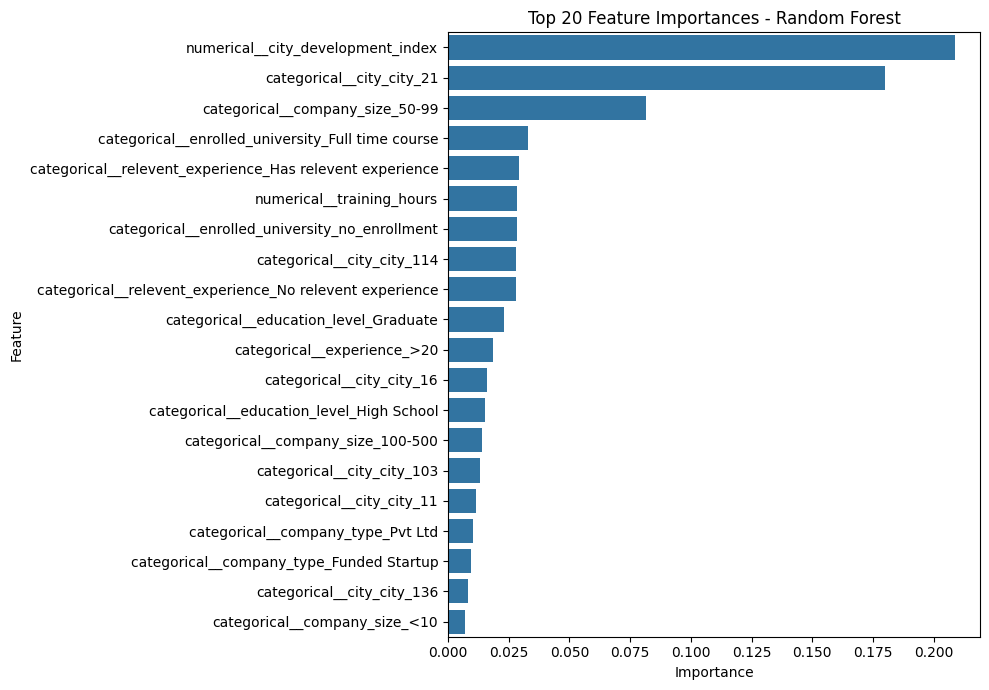

In [60]:
# Extract feature importance

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 20 features
top_features = feature_importance.head(20)

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()

### 5.11 Hyperparameter Tuning – Random Forest

Hyperparameter tuning is the process of finding the optimal configuration of a Machine Learning algorithm.

We will use RandomizedSearchCV to explore different combinations of Random Forest hyperparameters.

The model will be evaluated using 5-fold stratified cross-validation with F1-score as the optimization metric.

The objective is to improve the model's ability to identify candidates looking for a job change while maintaining a balance between precision and recall.

In [61]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

### 5.13 Creating Random Forest Pipeline

We will combine the preprocessing pipeline and Random Forest classifier into a single Machine Learning pipeline.

This ensures that preprocessing is performed independently within each cross-validation fold, preventing data leakage.

The pipeline will then be used for hyperparameter optimization.

In [62]:
# Create Random Forest pipeline

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


### 5.14 Defining Hyperparameter Search Space

We will define a range of hyperparameters for Random Forest.

RandomizedSearchCV will randomly select combinations from this search space and evaluate them using stratified 5-fold cross-validation.

The parameters include:

1. Number of decision trees (n_estimators).
2. Maximum tree depth (max_depth).
3. Minimum samples required to split a node (min_samples_split).
4. Minimum samples required at a leaf node (min_samples_leaf).
5. Number of features considered for each split (max_features).

In [63]:
# Define hyperparameter search space

param_grid = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

### 5.15 Configuring RandomizedSearchCV

We will configure RandomizedSearchCV to identify the best combination of Random Forest hyperparameters.

The configuration includes:

- 20 randomly selected hyperparameter combinations.
- 5-fold Stratified Cross-Validation.
- F1-score as the optimization metric.
- Parallel processing to reduce computation time.

The search will be performed using the training dataset only.

In [65]:
# Configure cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize RandomizedSearchCV

rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring='f1',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("RandomizedSearchCV configured successfully!")

RandomizedSearchCV configured successfully!


### 5.16 Executing Hyperparameter Tuning

We will now execute RandomizedSearchCV on the training dataset.

The algorithm will evaluate 20 different hyperparameter combinations using 5-fold cross-validation and identify the configuration that produces the highest average F1-score.

In [66]:
# Perform hyperparameter tuning

rf_random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Hyperparameter tuning completed!


### 5.17 Best Hyperparameters

After completing hyperparameter tuning, we will extract the best hyperparameter combination identified by RandomizedSearchCV.

We will also examine the highest cross-validation F1-score achieved during the search.

In [67]:
# Display best hyperparameters

print("Best Hyperparameters:")
print(rf_random_search.best_params_)

# Display best cross-validation score

print("\nBest Cross-Validation F1 Score:")
print(rf_random_search.best_score_)

Best Hyperparameters:
{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 20}

Best Cross-Validation F1 Score:
0.5902743336973457


### 5.18 Optimized Random Forest – Model Evaluation

We will retrieve the best estimator identified by RandomizedSearchCV and evaluate it using the testing dataset.

We will compare its performance with the original Random Forest model using Accuracy, Precision, Recall, F1-score and ROC-AUC.

This will help us determine whether hyperparameter tuning improved the model's predictive performance.

In [68]:
# Retrieve best model
best_rf_model = rf_random_search.best_estimator_

# Generate predictions
y_pred_best_rf = best_rf_model.predict(X_test)

# Generate prediction probabilities
y_prob_best_rf = best_rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
best_rf_metrics = {
    'Model': 'Optimized Random Forest',
    'Accuracy': accuracy_score(y_test, y_pred_best_rf),
    'Precision': precision_score(y_test, y_pred_best_rf),
    'Recall': recall_score(y_test, y_pred_best_rf),
    'F1 Score': f1_score(y_test, y_pred_best_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_best_rf)
}

print("Optimized Random Forest Performance:\n")

for metric, value in best_rf_metrics.items():
    if metric != 'Model':
        print(f"{metric}: {value:.4f}")

Optimized Random Forest Performance:

Accuracy: 0.7578
Precision: 0.5095
Recall: 0.7592
F1 Score: 0.6098
ROC-AUC: 0.8031


### 5.19 Original vs Optimized Random Forest

We will compare the original Random Forest model with the optimized Random Forest model.

The objective is to understand whether hyperparameter tuning improved the model's performance.

In [69]:
# Compare original and optimized Random Forest

rf_comparison_results = pd.DataFrame([
    rf_metrics,
    best_rf_metrics
])

rf_comparison_results.set_index('Model')

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Random Forest,0.765658,0.522459,0.694241,0.596223,0.799000
Optimized Random Forest,0.757829,0.509487,0.759162,0.609756,0.803087


### 5.20 Confusion Matrix – Optimized Random Forest

A confusion matrix provides a detailed breakdown of the model's classification performance.

It helps us identify:

1. True Negatives – Correctly predicted candidates not looking for a job change.
2. True Positives – Correctly predicted candidates looking for a job change.
3. False Positives – Candidates incorrectly predicted as looking for a job change.
4. False Negatives – Candidates incorrectly predicted as not looking for a job change.

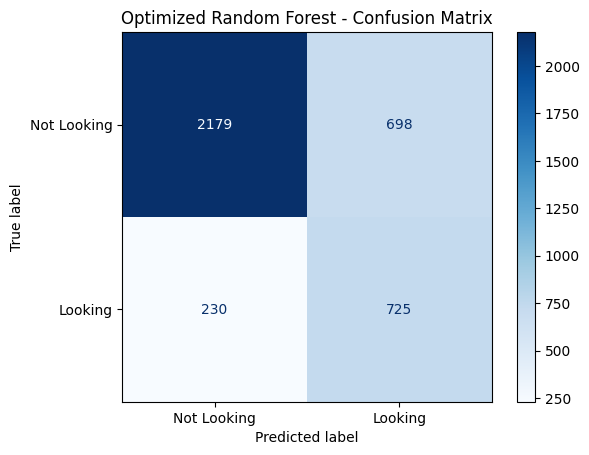

In [70]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_best_rf)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Looking', 'Looking']
)

disp.plot(cmap='Blues')
plt.title('Optimized Random Forest - Confusion Matrix')
plt.show()

### 5.21 Actual vs Predicted Values

We will compare the actual target values with the predictions generated by the optimized Random Forest model.

This will help us inspect individual predictions and understand how accurately the model classifies candidates.

In [72]:
# Compare actual and predicted values

comparison_best_rf = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_best_rf
})

comparison_best_rf.head(20)

,Actual,Predicted
0,0.0,0.0
1,1.0,1.0
2,0.0,0.0
3,1.0,0.0
4,1.0,1.0
5,0.0,1.0
6,0.0,0.0
7,0.0,0.0
8,1.0,1.0
9,0.0,0.0


In [73]:
print(classification_report(
    y_test,
    y_pred_best_rf,
    target_names=['Not Looking', 'Looking']
))

              precision    recall  f1-score   support

 Not Looking       0.90      0.76      0.82      2877
     Looking       0.51      0.76      0.61       955

    accuracy                           0.76      3832
   macro avg       0.71      0.76      0.72      3832
weighted avg       0.81      0.76      0.77      3832



## 6. Final Model Selection and Deployment

In this phase, we will prepare the selected model for deployment.

The complete pipeline will include:
1. Data preprocessing.
2. Missing value imputation.
3. Feature scaling.
4. Categorical encoding.
5. Optimized Random Forest classification.

Combining preprocessing and the trained model ensures that new input data undergoes the same transformations used during training.

In [74]:
# Select the optimized Random Forest pipeline

final_model = best_rf_model

print("Final model selected successfully!")

Final model selected successfully!


### 6.2 Saving the Trained Model

We will use Joblib to save the final Machine Learning pipeline.

The saved file will contain:
- Missing value imputation
- Feature scaling
- One-Hot Encoding
- Optimized Random Forest model

This allows us to load the trained pipeline later and make predictions on new candidate data.

In [75]:
import joblib

# Save the complete pipeline

joblib.dump(final_model, 'hr_job_change_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [76]:
import os

print("File Exists:", os.path.exists('hr_job_change_model.pkl'))
print("File Size:", round(os.path.getsize('hr_job_change_model.pkl') / 1024, 2), "KB")

File Exists: True
File Size: 6047.92 KB


### 6.3 Loading the Saved Model

We will load the saved Machine Learning pipeline using Joblib.

This verifies that the trained model can be reused without repeating the training and preprocessing steps.

In [77]:
# Load the saved model

loaded_model = joblib.load('hr_job_change_model.pkl')

print("Saved model loaded successfully!")

Saved model loaded successfully!


### 6.4 Making Predictions Using the Loaded Model

We will use the loaded model to generate predictions on the testing dataset.

The complete preprocessing pipeline will automatically transform the input features before generating predictions.

This verifies that the saved model can independently perform predictions without retraining.

In [78]:
# Generate predictions using loaded model

loaded_predictions = loaded_model.predict(X_test)

# Compare actual and predicted values

prediction_results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': loaded_predictions
})

prediction_results.head(20)

,Actual,Predicted
0,0.0,0.0
1,1.0,1.0
2,0.0,0.0
3,1.0,0.0
4,1.0,1.0
5,0.0,1.0
6,0.0,0.0
7,0.0,0.0
8,1.0,1.0
9,0.0,0.0


## 7. Project Conclusion

In this project, we developed a Machine Learning classification system to predict whether a candidate is looking for a job change using demographic, educational, professional, and company-related information.

### Key Activities Performed

1. Conducted Exploratory Data Analysis (EDA) to understand the dataset and identify important patterns.
2. Handled missing values using appropriate imputation techniques.
3. Applied Standard Scaling and One-Hot Encoding.
4. Trained four classification algorithms:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - XGBoost
5. Evaluated models using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
6. Analysed feature importance using Random Forest.
7. Performed hyperparameter tuning using RandomizedSearchCV with 5-fold cross-validation.
8. Saved and tested the complete optimized Machine Learning pipeline using Joblib.

### Final Model Performance

The optimized Random Forest model achieved the following results:

| Evaluation Metric | Score |
|---|---:|
| Accuracy | 75.78% |
| Precision | 50.95% |
| Recall | 75.92% |
| F1-score | 60.95% |
| ROC-AUC | 80.31% |

### Important Features

The most influential features identified by the original Random Forest model included:

- City Development Index
- City
- Company Size
- University Enrollment
- Relevant Experience
- Training Hours

### Model Deployment

The complete preprocessing and classification pipeline was saved as:

`hr_job_change_model.pkl`

The saved model was successfully loaded and tested on unseen data without retraining.

### Final Remarks

This project demonstrates the application of supervised Machine Learning techniques to a real-world classification problem.

The results indicate that candidate job-change intentions can be predicted using demographic, educational, and professional attributes. Further improvements could be explored through advanced feature engineering, threshold optimization, and additional model tuning.